<a href="https://colab.research.google.com/github/kazumah1/3Deeg/blob/main/EEG_3D_Clean_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEG-to-3D: concatenation vs FiLM

Run the cells from top to bottom in a **Colab GPU runtime**. This notebook evaluates your existing `andy_tiny_pn_v1` and `andy_tiny_pn_film_v1` checkpoints. It contains no training commands or data downloads.

**Question:** Can the tiny PointNet diffusion models reproduce training shapes, and do generated shapes respond to changes in EEG conditioning?

The recorded training runs used seven objects / 14 training examples and 5,000 steps. Concatenation joins the EEG embedding to features; FiLM uses it to scale and shift internal features. FiLM also has more parameters (1.40M vs 0.94M), so this is not a parameter-matched comparison.

Evaluation files replaced during this session are backed up first. Model checkpoints and training logs remain intact. This is a training-set sanity check, not a demonstration of unseen-object reconstruction.


## 1. Restore the Colab session



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import subprocess
import json
from pathlib import Path
from datetime import datetime, timezone

BASE = Path('/content/drive/MyDrive/3deeg')
RUNS = BASE / 'runs'
MODELS = {'Concatenation': 'andy_tiny_pn_v1', 'FiLM': 'andy_tiny_pn_film_v1'}
os.environ.update({
    'N3D_DATA': str(BASE / 'data/neuro-3d'),
    'N3D_RUNS': str(RUNS),
    'N3D_UPSTREAM': '/content/n3d_cache',
    'TORCH_EXTENSIONS_DIR': str(BASE / 'torch_extensions'),
})

import torch
if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > GPU, then rerun setup.')
print('GPU:', torch.cuda.get_device_name(0))
for path in [BASE / 'data/neuro-3d/packed', RUNS / 'enc_sub01/best.pt']:
    if not path.exists():
        raise FileNotFoundError(f'Missing saved input: {path}')
for run in MODELS.values():
    for filename in ['config.json', 'metrics.jsonl', 'last.pt']:
        if not (RUNS / run / filename).is_file():
            raise FileNotFoundError(RUNS / run / filename)

CODE = Path('/content/3deeg_clean_eval_1b341b5')
if not CODE.exists():
    subprocess.run(['git', 'clone', '--branch', 'colab-pipeline',
                    'https://github.com/kazumah1/3deeg', str(CODE)], check=True)
revision = subprocess.check_output(['git', '-C', str(CODE), 'rev-parse', 'HEAD'], text=True).strip()
if not revision.startswith('1b341b5'):
    subprocess.run(['git', '-C', str(CODE), 'checkout', '--detach', '1b341b5'], check=True)
os.chdir(CODE)
if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', '-r', 'requirements-colab.txt'], check=True)
from n3d import viz
print('Code commit:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())
print('Saved runs:', RUNS)


Mounted at /content/drive
GPU: Tesla T4
Code commit: 1b341b53c45f22d8d691af9b824ed093983c422d
Saved runs: /content/drive/MyDrive/3deeg/runs


## 2. Record the settings and preserve previous evaluation outputs

Inspect the saved configurations before comparing the runs. Both should use the same encoder, tiny subset, and training budget. This creates a timestamped results folder on Drive, including copies of existing evaluation files. Rerunning the notebook creates another session folder.


In [ ]:
import shutil
import hashlib

SESSION = BASE / 'evaluations' / datetime.now(timezone.utc).strftime('tiny_comparison_%Y%m%dT%H%M%S_%fZ')
SESSION.mkdir(parents=True, exist_ok=False)
configs = {}
provenance = {
    'code_commit': subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip(),
    'gpu': torch.cuda.get_device_name(0), 'torch': torch.__version__,
    'split': 'train', 'samples': 1, 'sampling_steps': 100,
    'checkpoint_hashes': {},
}
for label, run in MODELS.items():
    folder = RUNS / run
    configs[run] = json.loads((folder / 'config.json').read_text())
    print(f'\n{label}: {run}')
    print(json.dumps(configs[run], indent=2))
    backup = SESSION / 'before' / run
    backup.mkdir(parents=True)
    for pattern in ['config.json', 'metrics.jsonl', 'eval_*.json', 'swap_*.json', 'pred_*.npz']:
        for path in folder.glob(pattern):
            shutil.copy2(path, backup / path.name)
    digest = hashlib.sha256()
    with (folder / 'last.pt').open('rb') as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    provenance['checkpoint_hashes'][run] = {'last.pt': digest.hexdigest()}
(SESSION / 'configs.json').write_text(json.dumps(configs, indent=2))
(SESSION / 'provenance.json').write_text(json.dumps(provenance, indent=2))
print('\nThis session:', SESSION)



Concatenation: andy_tiny_pn_v1
{
  "cmd": "train",
  "run": "andy_tiny_pn_v1",
  "encoder_run": "enc_sub01",
  "cond_source": "eeg",
  "denoiser": "pointnet",
  "cond_mode": "concat",
  "width": 1.0,
  "voxel_res": 1.0,
  "data_root": null,
  "participants": [
    "sub01"
  ],
  "geometry": "point_cloud_simple",
  "split": "ours",
  "tiny": true,
  "max_steps": 5000,
  "batch_size": 8,
  "lr": 0.001,
  "log_every": 50,
  "eval_every": 500,
  "eval_steps": 50,
  "n_eval": 8,
  "ckpt_every": 1000,
  "snapshot_every": 5000,
  "keep_snapshots": 3,
  "milestone_every": 10000,
  "seed": 1234,
  "restart": false
}

FiLM: andy_tiny_pn_film_v1
{
  "cmd": "train",
  "run": "andy_tiny_pn_film_v1",
  "encoder_run": "enc_sub01",
  "cond_source": "eeg",
  "denoiser": "pointnet",
  "cond_mode": "film",
  "width": 1.0,
  "voxel_res": 1.0,
  "data_root": null,
  "participants": [
    "sub01"
  ],
  "geometry": "point_cloud_simple",
  "split": "ours",
  "tiny": true,
  "max_steps": 5000,
  "batch_size"

## 3. Compare the existing training curves

Lower Chamfer distance means closer point-cloud geometry. Denoising loss and Chamfer measure different things. The tiny training-time metric is called `val_cd`; do not interpret that name alone as evidence of held-out performance.


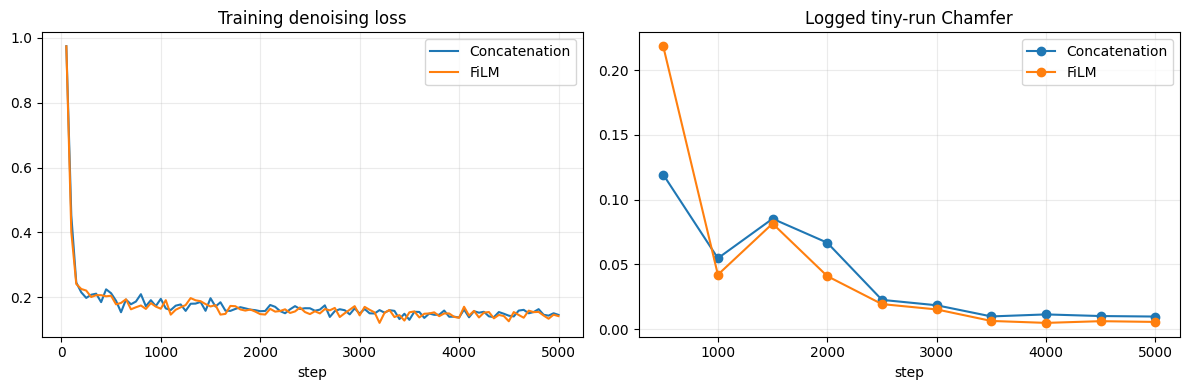

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

histories = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, run in MODELS.items():
    rows = [json.loads(line) for line in (RUNS / run / 'metrics.jsonl').read_text().splitlines() if line.strip()]
    frame = pd.DataFrame(rows)
    histories[run] = frame
    frame.dropna(subset=['step', 'loss']).plot(x='step', y='loss', ax=axes[0], label=label)
    frame.dropna(subset=['step', 'val_cd']).plot(x='step', y='val_cd', ax=axes[1], label=label, marker='o')
axes[0].set_title('Training denoising loss')
axes[1].set_title('Logged tiny-run Chamfer')
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
fig.savefig(SESSION / 'training_curves.png', dpi=160)


## 4. Regenerate training-set samples for both models

Use the same split, one sample per object, and 100 sampling steps. Commands stop on errors. These settings match across models; random-seed behavior depends on the repository defaults. A single generated sample per object is a preliminary comparison, not an estimate of variability.


In [ ]:
def run_diffusion(*arguments):
    subprocess.run([sys.executable, '-m', 'n3d.diffusion', *arguments], check=True, cwd=CODE)

for label, run in MODELS.items():
    print(f'\nSampling: {label}', flush=True)
    run_diffusion('sample', '--run', run, '--eval-split', 'train',
                  '--samples', '1', '--steps', '100')
    destination = SESSION / 'after' / run
    destination.mkdir(parents=True, exist_ok=True)
    for filename in ['eval_train_k1_s100.json', 'pred_train_k1_s100.npz']:
        shutil.copy2(RUNS / run / filename, destination / filename)



Sampling: Concatenation

Sampling: FiLM


## 5. Inspect generated shapes

Compare the same object identities across displays, using matched camera angles where possible. Check overall shape, thin parts, stray points, and whether different conditioning produces distinct objects. Visualization alone cannot show generalization.


In [ ]:
for label, run in MODELS.items():
    print(label)
    viz.show_samples(run, file='pred_train_k1_s100.npz', k=3)


Concatenation


FiLM


## 6. Run conditioning-swap checks for both models

Keep the trained model fixed and change its conditioning. Compare original, same-category donor, different-category donor, and zero embeddings. If swapping moves the generated shape toward the donor, that supports conditioning sensitivity. On training objects, memorized associations remain a possible explanation.


In [ ]:
for label, run in MODELS.items():
    print(f'\nSwap test: {label}', flush=True)
    run_diffusion('swap', '--run', run, '--eval-split', 'train', '--steps', '100')
    shutil.copy2(RUNS / run / 'swap_train_s100.json', SESSION / 'after' / run / 'swap_train_s100.json')



Swap test: Concatenation

Swap test: FiLM


## 7. Collect the results

The sampling table below uses the newly generated training-set evaluation files. The logged final training metric appears separately so it is not confused with the new sampling score. Raw swap results are shown without assuming their JSON layout.


In [ ]:
from IPython.display import display

summary = []
swap_results = {}
for label, run in MODELS.items():
    folder = SESSION / 'after' / run
    evaluation = json.loads((folder / 'eval_train_k1_s100.json').read_text())
    swap_results[run] = json.loads((folder / 'swap_train_s100.json').read_text())
    logged = histories[run].dropna(subset=['val_cd']).sort_values('step')
    summary.append({
        'model': label, 'run': run,
        'sampling_train_cd': evaluation.get('cd_mean_over_samples'),
        'sampling_train_f@0.02': evaluation.get('f@0.02_mean'),
        'evaluated_objects': evaluation.get('n_objects'),
        'last_logged_step': logged.iloc[-1]['step'] if len(logged) else None,
        'last_logged_cd': logged.iloc[-1]['val_cd'] if len(logged) else None,
    })
    print(f'\n{label}: sampling evaluation')
    print(json.dumps(evaluation, indent=2))
    print('Swap results')
    print(json.dumps(swap_results[run], indent=2))
table = pd.DataFrame(summary)
display(table)
table.to_csv(SESSION / 'comparison.csv', index=False)
(SESSION / 'swap_results.json').write_text(json.dumps(swap_results, indent=2))
print('Results saved to:', SESSION)



Concatenation: sampling evaluation
{
  "summary": {
    "split": "train",
    "n_objects": 7,
    "samples": 1,
    "steps": 100,
    "cd_mean_over_samples": 0.007214252171771867,
    "cd_best_of_k": 0.007214252171771867,
    "f@0.02_mean": 0.3686225704421849
  },
  "rows": [
    {
      "obj": 0,
      "sample": 0,
      "cd": 0.007952253334224224,
      "cd_acc": 0.007502411492168903,
      "cd_cov": 0.0004498417838476598,
      "cd_l1": 0.08230067789554596,
      "f@0.01": 0.10528547201808931,
      "f@0.02": 0.34142482074330716,
      "f@0.05": 0.6917792431652369
    },
    {
      "obj": 4,
      "sample": 0,
      "cd": 0.005464606918394566,
      "cd_acc": 0.005106108263134956,
      "cd_cov": 0.0003584988007787615,
      "cd_l1": 0.06771305948495865,
      "f@0.01": 0.13741185655715227,
      "f@0.02": 0.42909891989544896,
      "f@0.05": 0.788797747872734
    },
    {
      "obj": 141,
      "sample": 0,
      "cd": 0.005814240779727697,
      "cd_acc": 0.005224481225013733,


,model,run,sampling_train_cd,sampling_train_f@0.02,evaluated_objects,last_logged_step,last_logged_cd
0,Concatenation,andy_tiny_pn_v1,None,None,None,5000.0,0.009760
1,FiLM,andy_tiny_pn_film_v1,None,None,None,5000.0,0.005605


Results saved to: /content/drive/MyDrive/3deeg/evaluations/tiny_comparison_20261101T204230_966936Z


| Model | Mean training-set Chamfer ↓ |
|---|---:|
| Concatenation | 0.007214 |
| FiLM | **0.003616** |

In [4]:
from pathlib import Path

runs = Path("/content/drive/MyDrive/3deeg/runs")

for relative in [
    "enc_sub01/config.json",
    "enc_sub01/diagnostics.json",
    "baselines_sub01/baselines_summary.json",
]:
    print(f"\n--- {relative} ---")
    print((runs / relative).read_text())


--- enc_sub01/config.json ---
{
 "cmd": "train",
 "run": "enc_sub01",
 "data_root": null,
 "participants": [
  "sub01"
 ],
 "geometry": "point_cloud_simple",
 "split": "ours",
 "tiny": false,
 "seed": 0,
 "epochs": 200,
 "batch_size": 128,
 "lr": 0.001,
 "eval_every": 1,
 "restart": true,
 "zero_stream": "none",
 "select": "shape_nll",
 "snapshot_every": 20,
 "keep_snapshots": 0,
 "splits": {
  "train": 504,
  "val": 72,
  "test": 144
 }
}

--- enc_sub01/diagnostics.json ---
{
 "test_repeats_averaged": {
  "n": 144,
  "shape_top1": 0.041666666666666664,
  "shape_top5": 0.19444444444444445,
  "color_top1": 0.11805555555555555,
  "retr_cat_top1": 0.04861111111111111,
  "retr_cat_top5": 0.1111111111111111,
  "retr_inst_top1": 0.020833333333333332,
  "retr_inst_top5": 0.0763888888888889,
  "chance_shape_top1": 0.013888888888888888,
  "chance_inst_top1": 0.006944444444444444,
  "shape_nll": 4.105688095092773,
  "p_shape_top1": 0.015813008582615133,
  "p_shape_top5": 6.614046836921706e-07
 